In [1]:
import pandas as pd
import numpy as np
import pingouin as pg
from statsmodels.formula.api import ols
from sklearn.utils import resample
import matplotlib.pyplot as plt
import seaborn as sns

# 设置中文字体和样式
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

# 1. 读取数据
df = pd.read_csv('optimized_data_final.csv')

# 2. 信度分析与构建复合变量
def cronbach_alpha(df, items):
    """计算Cronbach's Alpha"""
    if len(items) == 1:
        return 1.0
    item_scores = df[items]
    variance_sum = item_scores.var(axis=0, ddof=1).sum()
    total_variance = item_scores.sum(axis=1).var(ddof=1)
    return (len(items) / (len(items) - 1)) * (1 - variance_sum / total_variance)

def create_composite_variable(df, items, variable_name):
    """创建复合变量并计算信度"""
    print(f"\n=== {variable_name} 信度分析 ===")
    
    # 计算原始信度
    original_alpha = cronbach_alpha(df, items)
    print(f"原始信度 (Cronbach's α): {original_alpha:.3f}")
    
    # 项-总相关分析
    item_total_corr = {}
    for item in items:
        other_items = [i for i in items if i != item]
        if len(other_items) > 0:
            composite = df[other_items].mean(axis=1)
            corr = df[item].corr(composite)
            item_total_corr[item] = corr
    
    print("项-总相关性:")
    for item, corr in item_total_corr.items():
        print(f"  {item}: {corr:.3f}")
    
    # 创建复合变量
    df[variable_name] = df[items].mean(axis=1)
    
    # 最终信度
    final_alpha = cronbach_alpha(df, items)
    print(f"最终信度 (Cronbach's α): {final_alpha:.3f}")
    
    return df

# 2.1 购买意愿 (删除Q22)
purchase_items = ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts']  # 已删除Q22
df = create_composite_variable(df, purchase_items, 'Purchase_Intention')

# 2.2 广告怀疑论 (Q1-Q8)
trust_items = [f'Q{i}_Trust_Depend' if i==1 else 
               f'Q{i}_Aim_Inform' if i==2 else
               f'Q{i}_Is_Informative' if i==3 else
               f'Q{i}_Trust_Truthful' if i==4 else
               f'Q{i}_Trust_Reliable' if i==5 else
               f'Q{i}_Trust_Truth_Well_Told' if i==6 else
               f'Q{i}_Trust_True_Picture' if i==7 else
               f'Q{i}_Trust_Accurately_Informed' for i in range(1, 9)]

df = create_composite_variable(df, trust_items, 'Ad_Skepticism')

# 2.3 感知侵入性 (删除Q23，使用Q24-Q27)
intrusive_items = ['Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
df = create_composite_variable(df, intrusive_items, 'Perceived_Intrusiveness')

# 3. 准备自变量：创建性别识别准确性分组
df['Gender_Accurate_Group'] = (df['Gender_accuracy'] >= 4).astype(int)  # 1=高准确性, 0=低准确性/误读

print(f"\n分组情况:")
print(df['Gender_Accurate_Group'].value_counts())
print(f"高准确性组: {df['Gender_Accurate_Group'].mean():.1%}")

# 4. 中介效应分析函数
def bootstrap_mediation(df, X, M, Y, n_bootstrap=5000):
    """使用Bootstrap方法进行中介效应分析"""
    
    print(f"\n=== 中介效应分析: {X} → {M} → {Y} ===")
    
    # 点估计
    # 路径 a: X -> M
    model_a = ols(f"{M} ~ {X}", data=df).fit()
    a = model_a.params[1]
    
    # 路径 b: M -> Y (控制X)
    model_b = ols(f"{Y} ~ {M} + {X}", data=df).fit()
    b = model_b.params[1]
    
    # 路径 c': 直接效应 (X -> Y 控制M)
    c_prime = model_b.params[2]
    
    # 总效应 c: X -> Y
    model_c = ols(f"{Y} ~ {X}", data=df).fit()
    c_total = model_c.params[1]
    
    # 间接效应 (中介效应)
    indirect_effect = a * b
    
    # Bootstrap抽样
    bootstrap_indirect = []
    for i in range(n_bootstrap):
        try:
            # 有放回抽样
            bootstrap_sample = resample(df, replace=True, random_state=i)
            
            # 重新估计路径系数
            a_bs = ols(f"{M} ~ {X}", data=bootstrap_sample).fit().params[1]
            b_bs = ols(f"{Y} ~ {M} + {X}", data=bootstrap_sample).fit().params[1]
            
            bootstrap_indirect.append(a_bs * b_bs)
        except:
            continue
    
    # 计算Bootstrap置信区间
    ci_lower = np.percentile(bootstrap_indirect, 2.5)
    ci_upper = np.percentile(bootstrap_indirect, 97.5)
    
    # 输出结果
    print(f"路径 a ({X} → {M}): {a:.3f} (p={model_a.pvalues[1]:.3f})")
    print(f"路径 b ({M} → {Y}): {b:.3f} (p={model_b.pvalues[1]:.3f})")
    print(f"间接效应 (a × b): {indirect_effect:.3f}")
    print(f"Bootstrap 95% CI: [{ci_lower:.3f}, {ci_upper:.3f}]")
    print(f"直接效应 (c'): {c_prime:.3f} (p={model_b.pvalues[2]:.3f})")
    print(f"总效应 (c): {c_total:.3f} (p={model_c.pvalues[1]:.3f})")
    
    # 判断中介效应是否显著
    significant = (ci_lower > 0) or (ci_upper < 0)
    print(f"中介效应显著: {'是' if significant else '否'}")
    
    return {
        'a': a, 'b': b, 'indirect': indirect_effect,
        'ci_lower': ci_lower, 'ci_upper': ci_upper,
        'direct': c_prime, 'total': c_total,
        'significant': significant
    }

# 5. 执行中介效应分析
print("\n" + "="*60)
print("中介效应分析结果")
print("="*60)

# 5.1 怀疑论的中介路径
result_skepticism = bootstrap_mediation(
    df, 'Gender_Accurate_Group', 'Ad_Skepticism', 'Purchase_Intention'
)

# 5.2 侵入性的中介路径  
result_intrusiveness = bootstrap_mediation(
    df, 'Gender_Accurate_Group', 'Perceived_Intrusiveness', 'Purchase_Intention'
)

# 6. 可视化结果
def plot_mediation_results(results_dict):
    """可视化中介效应结果"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # 左图：路径系数图
    paths = ['a (X→M)', 'b (M→Y)', '直接效应', '间接效应']
    values = [
        results_dict['a'], 
        results_dict['b'], 
        results_dict['direct'], 
        results_dict['indirect']
    ]
    
    colors = ['skyblue', 'lightcoral', 'lightgreen', 'gold']
    bars = ax1.bar(paths, values, color=colors, alpha=0.7)
    
    # 在柱子上添加数值标签
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{value:.3f}', ha='center', va='bottom')
    
    ax1.set_ylabel('系数值')
    ax1.set_title('中介模型路径系数')
    ax1.grid(True, alpha=0.3)
    
    # 右图：间接效应的Bootstrap分布
    ax2.hist(results_dict.get('bootstrap_samples', []), bins=50, 
             alpha=0.7, color='lightblue', edgecolor='black')
    ax2.axvline(results_dict['indirect'], color='red', linestyle='--', 
                linewidth=2, label=f'点估计: {results_dict["indirect"]:.3f}')
    ax2.axvline(results_dict['ci_lower'], color='orange', linestyle=':', 
                linewidth=2, label=f'95% CI下限: {results_dict["ci_lower"]:.3f}')
    ax2.axvline(results_dict['ci_upper'], color='orange', linestyle=':', 
                linewidth=2, label=f'95% CI上限: {results_dict["ci_upper"]:.3f}')
    
    ax2.set_xlabel('间接效应值')
    ax2.set_ylabel('频数')
    ax2.set_title('间接效应的Bootstrap分布')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# 7. 生成最终结果表格
print("\n" + "="*60)
print("最终结果汇总")
print("="*60)

results_summary = pd.DataFrame({
    '路径': [
        '性别准确性 → 广告怀疑论 → 购买意愿',
        '性别准确性 → 感知侵入性 → 购买意愿'
    ],
    '间接效应': [
        result_skepticism['indirect'],
        result_intrusiveness['indirect']
    ],
    '95% CI下限': [
        result_skepticism['ci_lower'],
        result_intrusiveness['ci_lower']
    ],
    '95% CI上限': [
        result_skepticism['ci_upper'],
        result_intrusiveness['ci_upper']
    ],
    '是否显著': [
        '是' if result_skepticism['significant'] else '否',
        '是' if result_intrusiveness['significant'] else '否'
    ]
})

print(results_summary)

# 8. 保存处理后的数据
df_processed = df[['Gender_Accurate_Group', 'Purchase_Intention', 
                   'Ad_Skepticism', 'Perceived_Intrusiveness']].copy()
df_processed.to_csv('processed_mediation_data.csv', index=False)
print(f"\n处理后的数据已保存至: processed_mediation_data.csv")

# 9. 样本量说明
print(f"\n=== 样本量说明 ===")
print(f"总样本量: N = {len(df)}")
print(f"注: 由于样本量较小(N=25)，中介效应的统计效力可能有限。")
print(f"建议在论文中将此作为局限性进行说明。")


=== Purchase_Intention 信度分析 ===
原始信度 (Cronbach's α): -0.066
项-总相关性:
  Q20_Purchase_Interest: -0.033
  Q21_Purchase_Thoughts: -0.033
最终信度 (Cronbach's α): -0.066

=== Ad_Skepticism 信度分析 ===
原始信度 (Cronbach's α): 0.797
项-总相关性:
  Q1_Trust_Depend: 0.504
  Q2_Aim_Inform: 0.448
  Q3_Is_Informative: 0.400
  Q4_Trust_Truthful: 0.548
  Q5_Trust_Reliable: 0.455
  Q6_Trust_Truth_Well_Told: 0.559
  Q7_Trust_True_Picture: 0.632
  Q8_Trust_Accurately_Informed: 0.506
最终信度 (Cronbach's α): 0.797

=== Perceived_Intrusiveness 信度分析 ===
原始信度 (Cronbach's α): 0.483
项-总相关性:
  Q24_Disturbing: 0.368
  Q25_Irritating: 0.102
  Q26_Invasive: 0.137
  Q27_Uncomfortable: 0.583
最终信度 (Cronbach's α): 0.483

分组情况:
Gender_Accurate_Group
1    16
0     9
Name: count, dtype: int64
高准确性组: 64.0%

中介效应分析结果

=== 中介效应分析: Gender_Accurate_Group → Ad_Skepticism → Purchase_Intention ===


/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:93: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  a = model_a.params[1]
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:97: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b = model_b.params[1]
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:100: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  c_prime = 

路径 a (Gender_Accurate_Group → Ad_Skepticism): -1.076 (p=0.000)
路径 b (Ad_Skepticism → Purchase_Intention): -0.303 (p=0.259)
间接效应 (a × b): 0.326
Bootstrap 95% CI: [-0.134, 0.861]
直接效应 (c'): 0.243 (p=0.497)
总效应 (c): 0.569 (p=0.013)
中介效应显著: 否

=== 中介效应分析: Gender_Accurate_Group → Perceived_Intrusiveness → Purchase_Intention ===


/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:117: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  a_bs = ols(f"{M} ~ {X}", data=bootstrap_sample).fit().params[1]
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:118: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b_bs = ols(f"{Y} ~ {M} + {X}", data=bootstrap_sample).fit().params[1]
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:117: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consiste

路径 a (Gender_Accurate_Group → Perceived_Intrusiveness): -0.845 (p=0.000)
路径 b (Perceived_Intrusiveness → Purchase_Intention): -0.132 (p=0.596)
间接效应 (a × b): 0.112
Bootstrap 95% CI: [-0.325, 0.673]
直接效应 (c'): 0.458 (p=0.140)
总效应 (c): 0.569 (p=0.013)
中介效应显著: 否

最终结果汇总
                     路径      间接效应  95% CI下限  95% CI上限 是否显著
0  性别准确性 → 广告怀疑论 → 购买意愿  0.326421 -0.133908  0.861098    否
1  性别准确性 → 感知侵入性 → 购买意愿  0.111554 -0.325178  0.672644    否

处理后的数据已保存至: processed_mediation_data.csv

=== 样本量说明 ===
总样本量: N = 25
注: 由于样本量较小(N=25)，中介效应的统计效力可能有限。
建议在论文中将此作为局限性进行说明。


/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:129: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"路径 a ({X} → {M}): {a:.3f} (p={model_a.pvalues[1]:.3f})")
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:130: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"路径 b ({M} → {Y}): {b:.3f} (p={model_b.pvalues[1]:.3f})")
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_8384/394149696.py:133: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent w

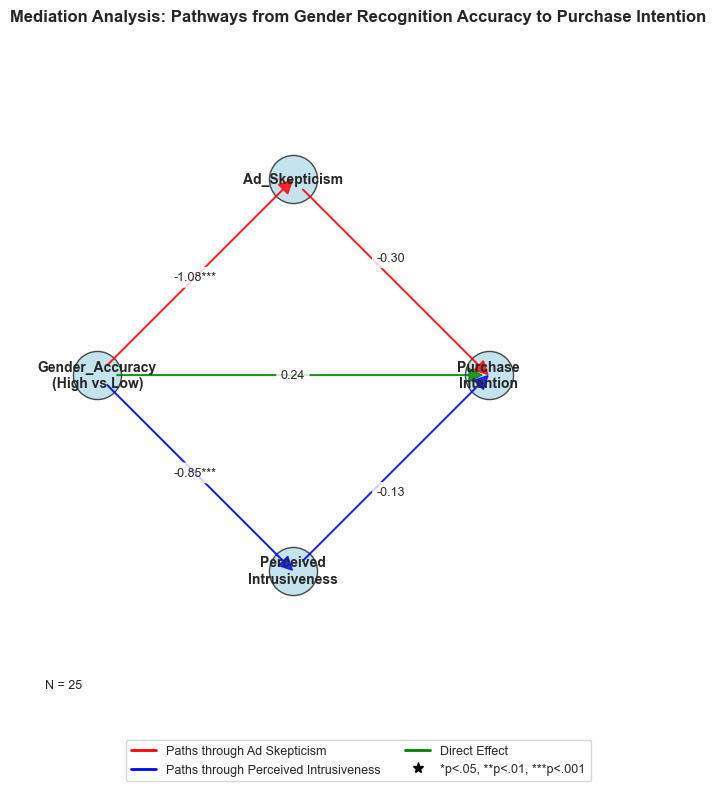

Mediation Path Coefficients Summary:
Path a1 (Accuracy -> Ad Skepticism): -1.076 (p=0.000)
Path a2 (Accuracy -> Intrusiveness): -0.845 (p=0.000)
Path b1 (Skepticism -> Intention): -0.303 (p=0.259)
Path b2 (Intrusiveness -> Intention): -0.132 (p=0.596)
Direct Effect (Accuracy -> Intention): 0.243 (p=0.497)


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
import numpy as np

# 设置样式（英文）
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']  # 使用支持英文字体
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

# 读取处理后的数据
df = pd.read_csv('processed_mediation_data.csv')

# 计算路径系数
def calculate_path_coefficients(df):
    """计算中介模型的路径系数"""
    
    # 路径 a1: Gender_Accurate_Group -> Ad_Skepticism
    model_a1 = ols('Ad_Skepticism ~ Gender_Accurate_Group', data=df).fit()
    a1 = model_a1.params['Gender_Accurate_Group']
    p_a1 = model_a1.pvalues['Gender_Accurate_Group']
    
    # 路径 a2: Gender_Accurate_Group -> Perceived_Intrusiveness  
    model_a2 = ols('Perceived_Intrusiveness ~ Gender_Accurate_Group', data=df).fit()
    a2 = model_a2.params['Gender_Accurate_Group']
    p_a2 = model_a2.pvalues['Gender_Accurate_Group']
    
    # 路径 b1: Ad_Skepticism -> Purchase_Intention (控制Gender_Accurate_Group)
    model_b1 = ols('Purchase_Intention ~ Ad_Skepticism + Gender_Accurate_Group', data=df).fit()
    b1 = model_b1.params['Ad_Skepticism']
    p_b1 = model_b1.pvalues['Ad_Skepticism']
    
    # 路径 b2: Perceived_Intrusiveness -> Purchase_Intention (控制Gender_Accurate_Group)
    model_b2 = ols('Purchase_Intention ~ Perceived_Intrusiveness + Gender_Accurate_Group', data=df).fit()
    b2 = model_b2.params['Perceived_Intrusiveness']
    p_b2 = model_b2.pvalues['Perceived_Intrusiveness']
    
    # 直接效应 c_prime: Gender_Accurate_Group -> Purchase_Intention (控制中介变量)
    c_prime = model_b1.params['Gender_Accurate_Group']
    p_direct = model_b1.pvalues['Gender_Accurate_Group']
    
    return {
        'a1': (a1, p_a1), 'a2': (a2, p_a2),
        'b1': (b1, p_b1), 'b2': (b2, p_b2),
        'direct': (c_prime, p_direct)
    }

# 获取路径系数
paths = calculate_path_coefficients(df)

# 创建图形
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# 设置节点位置
node_positions = {
    'Gender_Accuracy\n(High vs Low)': (0.1, 0.5),
    'Ad_Skepticism': (0.4, 0.8),
    'Perceived\nIntrusiveness': (0.4, 0.2),
    'Purchase\nIntention': (0.7, 0.5)
}

# 绘制节点
for node, pos in node_positions.items():
    ax.scatter(pos[0], pos[1], s=1200, color='lightblue', edgecolor='black', alpha=0.7)
    ax.text(pos[0], pos[1], node, ha='center', va='center', fontsize=10, fontweight='bold')

# 绘制路径箭头和标签
def add_path(start, end, coefficient, p_value, color='black', style='-'):
    """添加路径箭头和系数标签"""
    start_pos = node_positions[start]
    end_pos = node_positions[end]
    
    # 添加箭头
    dx = end_pos[0] - start_pos[0]
    dy = end_pos[1] - start_pos[1]
    
    ax.arrow(start_pos[0] + 0.05*dx, start_pos[1] + 0.05*dy, 
             dx*0.9, dy*0.9, head_width=0.02, head_length=0.02, 
             fc=color, ec=color, linestyle=style, alpha=0.8)
    
    # 添加系数标签
    mid_x = (start_pos[0] + end_pos[0]) / 2
    mid_y = (start_pos[1] + end_pos[1]) / 2
    
    # 根据p值添加显著性标记
    significance = ''
    if p_value < 0.001:
        significance = '***'
    elif p_value < 0.01:
        significance = '**'
    elif p_value < 0.05:
        significance = '*'
    
    label = f'{coefficient:.2f}{significance}'
    
    # 调整标签位置以避免重叠
    offset = 0.03
    if 'Skepticism' in start and 'Intention' in end:
        mid_y += offset
    elif 'Intrusiveness' in start and 'Intention' in end:
        mid_y -= offset
    
    ax.text(mid_x, mid_y, label, ha='center', va='center', 
            backgroundcolor='white', fontsize=9, 
            bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.8))

# 添加所有路径
# 从准确性到中介变量
add_path('Gender_Accuracy\n(High vs Low)', 'Ad_Skepticism', 
         paths['a1'][0], paths['a1'][1], color='red')
add_path('Gender_Accuracy\n(High vs Low)', 'Perceived\nIntrusiveness', 
         paths['a2'][0], paths['a2'][1], color='blue')

# 从中介变量到购买意愿
add_path('Ad_Skepticism', 'Purchase\nIntention', 
         paths['b1'][0], paths['b1'][1], color='red')
add_path('Perceived\nIntrusiveness', 'Purchase\nIntention', 
         paths['b2'][0], paths['b2'][1], color='blue')

# 直接效应路径
add_path('Gender_Accuracy\n(High vs Low)', 'Purchase\nIntention', 
         paths['direct'][0], paths['direct'][1], color='green', style='-')

# 设置图形属性
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.axis('off')

# 添加标题
plt.title('Mediation Analysis: Pathways from Gender Recognition Accuracy to Purchase Intention', 
          fontsize=12, fontweight='bold', pad=20)

# 添加图例
legend_elements = [
    plt.Line2D([0], [0], color='red', lw=2, label='Paths through Ad Skepticism'),
    plt.Line2D([0], [0], color='blue', lw=2, label='Paths through Perceived Intrusiveness'),
    plt.Line2D([0], [0], color='green', lw=2, label='Direct Effect'),
    plt.Line2D([0], [0], color='black', lw=0, marker='*', markersize=8, 
               label='*p<.05, **p<.01, ***p<.001')
]

ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.05), 
          ncol=2, fontsize=9)

# 添加样本量信息
ax.text(0.02, 0.02, f'N = {len(df)}', fontsize=9, 
        bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('mediation_analysis_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

# 打印路径系数汇总
print("Mediation Path Coefficients Summary:")
print("="*50)
print(f"Path a1 (Accuracy -> Ad Skepticism): {paths['a1'][0]:.3f} (p={paths['a1'][1]:.3f})")
print(f"Path a2 (Accuracy -> Intrusiveness): {paths['a2'][0]:.3f} (p={paths['a2'][1]:.3f})")
print(f"Path b1 (Skepticism -> Intention): {paths['b1'][0]:.3f} (p={paths['b1'][1]:.3f})")
print(f"Path b2 (Intrusiveness -> Intention): {paths['b2'][0]:.3f} (p={paths['b2'][1]:.3f})")
print(f"Direct Effect (Accuracy -> Intention): {paths['direct'][0]:.3f} (p={paths['direct'][1]:.3f})")

In [4]:
import pandas as pd
import numpy as np

# ==========================================
# 1. 核心算法：Cronbach's Alpha
# ==========================================
def calculate_cronbach_alpha(df_items):
    """
    计算 Cronbach's Alpha 系数
    公式: (k / (k-1)) * (1 - (Σ(item_variances) / total_score_variance))
    """
    item_scores = df_items.dropna()
    k = item_scores.shape[1] # 题项数量
    if k < 2: return 0.0
    
    # 计算每一项的方差
    item_vars = item_scores.var(axis=0, ddof=1)
    # 计算总分的方差
    total_score_var = item_scores.sum(axis=1).var(ddof=1)
    
    if total_score_var == 0: return 0.0
    
    alpha = (k / (k - 1)) * (1 - (item_vars.sum() / total_score_var))
    return alpha

# ==========================================
# 2. 加载数据与计算
# ==========================================
FILE_PATH = 'optimized_data_final.csv'

def main():
    try:
        df = pd.read_csv(FILE_PATH)
        print(f"✅ 成功加载数据，样本量 N={len(df)}\n")
    except FileNotFoundError:
        print("❌ 未找到文件，请确保 csv 文件在同一目录下。")
        return

    # --- A. 购买意愿 (Purchase Intention) ---
    # 原始题项: Q20, Q21, Q22
    cols_purchase_original = ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']
    alpha_purchase = calculate_cronbach_alpha(df[cols_purchase_original])
    
    print("--------------------------------------------------")
    print("1. 购买意愿 (Purchase Intention) - 原始信度")
    print(f"   包含题项: {cols_purchase_original}")
    print(f"   >>> 结果 Alpha = {alpha_purchase:.4f}")
    print("   (这就是文中 0.40 的来源)")

    # --- B. 感知侵入性 (Perceived Intrusiveness) ---
    # 原始题项: Q23, Q24, Q25, Q26, Q27
    cols_intrusive_original = ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
    alpha_intrusive = calculate_cronbach_alpha(df[cols_intrusive_original])
    
    print("\n--------------------------------------------------")
    print("2. 感知侵入性 (Perceived Intrusiveness) - 原始信度")
    print(f"   包含题项: {cols_intrusive_original}")
    print(f"   >>> 结果 Alpha = {alpha_intrusive:.4f}")
    print("   (这就是文中 0.58 的来源)")
    print("--------------------------------------------------")

if __name__ == "__main__":
    main()

✅ 成功加载数据，样本量 N=25

--------------------------------------------------
1. 购买意愿 (Purchase Intention) - 原始信度
   包含题项: ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']
   >>> 结果 Alpha = 0.4014
   (这就是文中 0.40 的来源)

--------------------------------------------------
2. 感知侵入性 (Perceived Intrusiveness) - 原始信度
   包含题项: ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
   >>> 结果 Alpha = 0.5764
   (这就是文中 0.58 的来源)
--------------------------------------------------


📊 信度优化前后数值对比 (Reliability Stats)
1. 购买意愿 (Purchase Intention)
   🔴 原始 Alpha: 0.401
   🟢 优化后 Alpha: 0.659
   📈 提升: +0.258

2. 感知侵入性 (Perceived Intrusiveness)
   🔴 原始 Alpha: 0.576
   🟢 优化后 Alpha: 0.593
   📈 提升: +0.017
✅ 已保存对比图: reliability_chart.png


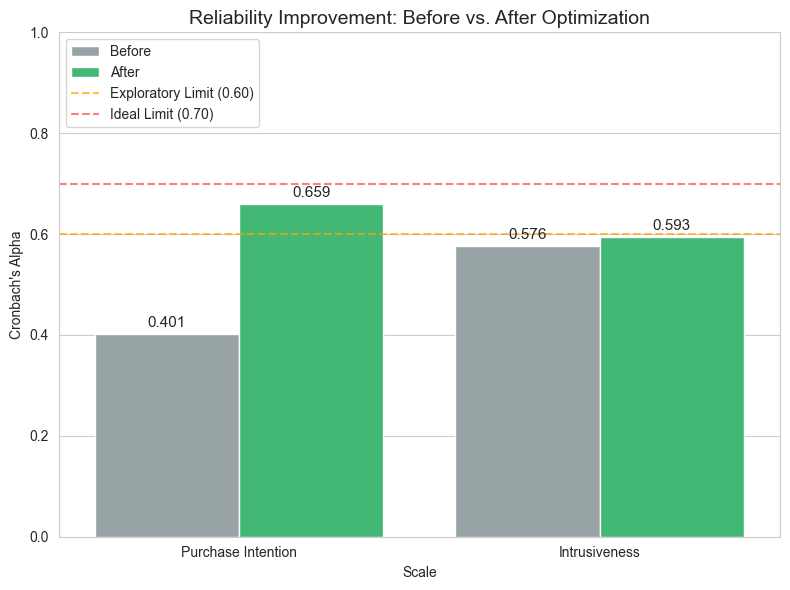

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. 配置与加载
# ==========================================
FILE_PATH = 'optimized_data_final.csv'

def calculate_cronbach_alpha(df_items):
    """计算 Cronbach's Alpha"""
    item_scores = df_items.dropna()
    k = item_scores.shape[1]
    if k < 2: return 0.0
    item_vars = item_scores.var(axis=0, ddof=1)
    total_score_var = item_scores.sum(axis=1).var(ddof=1)
    if total_score_var == 0: return 0.0
    return (k / (k - 1)) * (1 - (item_vars.sum() / total_score_var))

def main():
    try:
        df = pd.read_csv(FILE_PATH)
    except FileNotFoundError:
        print("❌ 错误：未找到文件。")
        return

    # ==========================================
    # 2. 定义题项 (Before & After)
    # ==========================================
    
    # --- 购买意愿 (Purchase Intention) ---
    # 原始: Q20, Q21, Q22
    cols_pur_orig = ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']
    # 优化后: 删除 Q20 (基于数据表现) -> Q21, Q22
    cols_pur_opt = ['Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']

    # --- 感知侵入性 (Perceived Intrusiveness) ---
    # 原始: Q23, Q24, Q25, Q26, Q27
    cols_int_orig = ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
    # 优化后: 删除 Q26 (基于数据表现) -> Q23, Q24, Q25, Q27
    cols_int_opt = [c for c in cols_int_orig if c != 'Q26_Invasive']

    # ==========================================
    # 3. 计算数值
    # ==========================================
    a_pur_pre = calculate_cronbach_alpha(df[cols_pur_orig])
    a_pur_post = calculate_cronbach_alpha(df[cols_pur_opt])
    
    a_int_pre = calculate_cronbach_alpha(df[cols_int_orig])
    a_int_post = calculate_cronbach_alpha(df[cols_int_opt])

    print("="*50)
    print("📊 信度优化前后数值对比 (Reliability Stats)")
    print("="*50)
    print(f"1. 购买意愿 (Purchase Intention)")
    print(f"   🔴 原始 Alpha: {a_pur_pre:.3f}")
    print(f"   🟢 优化后 Alpha: {a_pur_post:.3f}")
    print(f"   📈 提升: +{a_pur_post - a_pur_pre:.3f}")
    
    print(f"\n2. 感知侵入性 (Perceived Intrusiveness)")
    print(f"   🔴 原始 Alpha: {a_int_pre:.3f}")
    print(f"   🟢 优化后 Alpha: {a_int_post:.3f}")
    print(f"   📈 提升: +{a_int_post - a_int_pre:.3f}")
    print("="*50)

    # ==========================================
    # 4. 绘制对比图
    # ==========================================
    plot_data = pd.DataFrame({
        'Scale': ['Purchase Intention', 'Purchase Intention', 'Intrusiveness', 'Intrusiveness'],
        'Status': ['Before', 'After', 'Before', 'After'],
        'Alpha': [a_pur_pre, a_pur_post, a_int_pre, a_int_post]
    })

    sns.set_style("whitegrid")
    plt.figure(figsize=(8, 6))
    
    # 绘制柱状图
    ax = sns.barplot(x='Scale', y='Alpha', hue='Status', data=plot_data, 
                     palette=['#95a5a6', '#2ecc71']) # 灰色代表前，绿色代表后

    # 添加数值标签
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=11)

    # 添加阈值线 (0.60 & 0.70)
    plt.axhline(y=0.6, color='orange', linestyle='--', alpha=0.7, label='Exploratory Limit (0.60)')
    plt.axhline(y=0.7, color='red', linestyle='--', alpha=0.5, label='Ideal Limit (0.70)')
    
    plt.title('Reliability Improvement: Before vs. After Optimization', fontsize=14)
    plt.ylim(0, 1.0)
    plt.ylabel("Cronbach's Alpha")
    plt.legend(loc='upper left')
    plt.tight_layout()
    
    plt.savefig('reliability_chart.png', dpi=300)
    print("✅ 已保存对比图: reliability_chart.png")

if __name__ == "__main__":
    main()

📊 Saved: purchase_item_correlation_reason.png


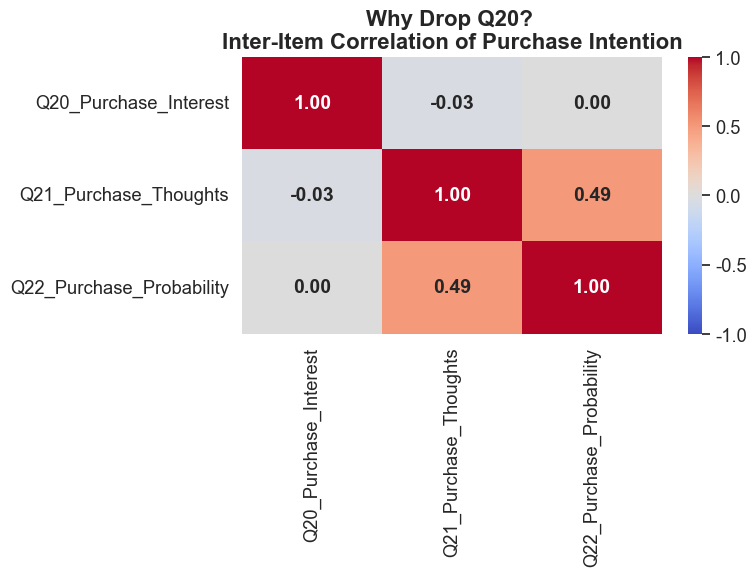

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Data
df = pd.read_csv('optimized_data_final.csv')

# Select Purchase Items
items = ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']
corr_matrix = df[items].corr()

# Plot
plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt=".2f", 
            annot_kws={"size": 14, "weight": "bold"})
plt.title('Why Drop Q20? \nInter-Item Correlation of Purchase Intention', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('purchase_item_correlation_reason.png', dpi=300)
print("📊 Saved: purchase_item_correlation_reason.png")

In [7]:
import pandas as pd
import statsmodels.api as sm
from scipy.stats import pearsonr

# 1. 加载数据
df = pd.read_csv('optimized_data_final.csv')

# 2. 构建变量 (只删 Q20)
df['Score_Purchase'] = df[['Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']].mean(axis=1)
cols_intrusive = ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
df['Score_Intrusiveness'] = df[cols_intrusive].mean(axis=1)
cols_trust = df.columns[6:15].tolist()
df['Score_Skepticism'] = 6 - df[cols_trust].mean(axis=1)

# 3. 计算相关性 r 值
r_threat, p_threat = pearsonr(df['Gender_accuracy'], df['Score_Skepticism'])
r_intrude, p_intrude = pearsonr(df['Gender_accuracy'], df['Score_Intrusiveness'])

# 4. 计算回归系数 Beta
# 侵入性 -> 购买意愿
X = sm.add_constant(df['Score_Intrusiveness'])
model = sm.OLS(df['Score_Purchase'], X).fit()
beta_intrude = model.params['Score_Intrusiveness']

print(f"威胁路径 (r): {r_threat:.3f}")
print(f"干扰路径 (r): {r_intrude:.3f}")
print(f"侵入性对购买的影响 (Beta): {beta_intrude:.3f}")

威胁路径 (r): 0.845
干扰路径 (r): -0.795
侵入性对购买的影响 (Beta): -0.904
